# 03 – Dự báo (μ, Σ) và đường biên hiệu quả – TV4

Notebook chỉ để **xem và vẽ**. Mọi tính toán nằm trong `src/tv4_forecast.py`, `src/estimators.py`, `src/optimizers.py`
(để `run_all.py` chạy lại được). Mọi con số trong report 5.4 lấy từ các file `outputs/` dưới đây.

- `outputs/forecast_error.csv` – RMSE, MAE, độ chệch của biến động dự báo (Σ mẫu vs Ledoit–Wolf) so với biến động thực tế quý sau
- `outputs/forecast_error_detail.csv` – từng kỳ, từng mã / danh mục
- `outputs/estimation_diagnostics.csv` – độ dài cửa sổ, hệ số co Ledoit–Wolf, số mã có tỷ trọng > 0 mỗi kỳ
- `outputs/frontier.csv` – đường biên hiệu quả có ràng buộc tại 30/09/2026 (cho Q4/2026)

⚠️ Mặc định chỉ chạy **validation 2020–2021**. Phần test chỉ chạy sau khi đóng băng 03/11 (ô cuối).

*Kết quả là bài tập học thuật, không phải khuyến nghị đầu tư.*

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tv4_forecast
from config import load

cfg = load()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("μ:", cfg["estimation"]["expected_returns"], "| Σ:", cfg["estimation"]["covariance"],
      "| w_max:", cfg["portfolio"]["w_max"])

μ: capm | Σ: ledoit_wolf | w_max: 0.1


In [2]:
# Chạy lại toàn bộ tính toán (validation + đường biên) rồi đọc file
for p in tv4_forecast.run("validation", with_frontier=True):
    print("ghi", p.relative_to(ROOT))
summ = pd.read_csv(ROOT / "outputs/forecast_error.csv")
det = pd.read_csv(ROOT / "outputs/forecast_error_detail.csv", parse_dates=["decision_date"])
diag = pd.read_csv(ROOT / "outputs/estimation_diagnostics.csv", parse_dates=["decision_date"])
fr = pd.read_csv(ROOT / "outputs/frontier.csv")

ghi outputs\forecast_error.csv
ghi outputs\forecast_error_detail.csv
ghi outputs\estimation_diagnostics.csv
ghi outputs\frontier.csv


## 1. Sai số dự báo biến động: Ledoit–Wolf vs Σ mẫu (validation)

In [3]:
tab = summ.pivot(index="target", columns="cov_method", values=["rmse", "mae", "bias"]).round(4)
tab[("rmse", "LW_tot_hon_pct")] = ((1 - summ.pivot(index="target", columns="cov_method", values="rmse")["ledoit_wolf"]
                                  / summ.pivot(index="target", columns="cov_method", values="rmse")["sample"]) * 100).round(2)
tab

rmse                 mae                bias          \
cov_method   ledoit_wolf  sample ledoit_wolf  sample ledoit_wolf  sample   
target                                                                     
equal_weight      0.0952  0.0933      0.0753  0.0740     -0.0416 -0.0382   
min_variance      0.0832  0.0821      0.0601  0.0594     -0.0431 -0.0413   
risk_parity       0.0906  0.0888      0.0692  0.0679     -0.0427 -0.0398   
stock             0.1206  0.1205      0.0887  0.0887     -0.0525 -0.0525   

                       rmse  
cov_method   LW_tot_hon_pct  
target                       
equal_weight          -2.04  
min_variance          -1.43  
risk_parity           -1.98  
stock                 -0.10

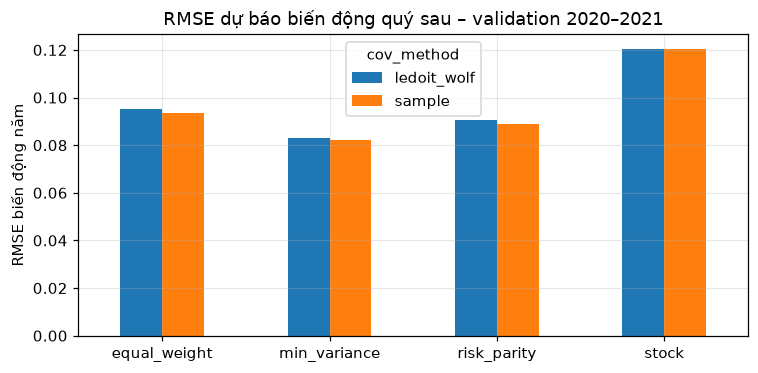

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
p = summ.pivot(index="target", columns="cov_method", values="rmse")
p.plot.bar(ax=ax, rot=0)
ax.set_ylabel("RMSE biến động năm"); ax.set_xlabel("")
ax.set_title("RMSE dự báo biến động quý sau – validation 2020–2021")
fig.tight_layout(); fig.savefig(FIG / "tv4_rmse_validation.png"); plt.show()

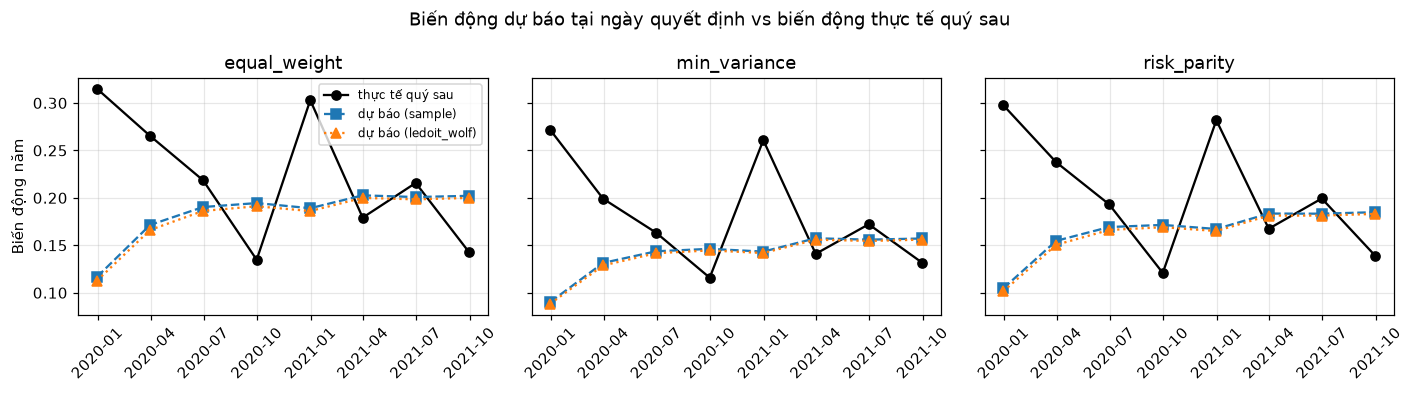

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, tgt in zip(axes, ["equal_weight", "min_variance", "risk_parity"]):
    d = det[det["target"] == tgt]
    real = d[d["cov_method"] == "sample"].set_index("decision_date")["realized_vol"]
    ax.plot(real.index, real, "k-o", label="thực tế quý sau")
    for cm, st in (("sample", "--s"), ("ledoit_wolf", ":^")):
        f = d[d["cov_method"] == cm].set_index("decision_date")["forecast_vol"]
        ax.plot(f.index, f, st, label=f"dự báo ({cm})")
    ax.set_title(tgt); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Biến động năm"); axes[0].legend(fontsize=8)
fig.suptitle("Biến động dự báo tại ngày quyết định vs biến động thực tế quý sau")
fig.tight_layout(); fig.savefig(FIG / "tv4_forecast_vs_realized.png"); plt.show()

**Đọc kết quả:** quý 2020Q1 (COVID) là điểm ngoại lai – mọi dự báo dựa trên lịch sử đều thấp hơn thực tế.
Kiểm tra độ vững bằng cách bỏ quý đó (chỉ để diễn giải, không dùng để chọn lại thiết kế ngoài quy trình đã thống nhất).

In [6]:
first = det["decision_date"].min()
ex = det[det["decision_date"] != first]
rob = ex.groupby(["target", "cov_method"])["error"].apply(lambda e: np.sqrt(np.mean(e**2))).unstack().round(4)
rob.columns.name = "RMSE bỏ quý đầu"
rob

RMSE bỏ quý đầu,ledoit_wolf,sample
target,,
equal_weight,0.0673,0.0660
min_variance,0.0555,0.0546
risk_parity,0.0620,0.0607
stock,0.0887,0.0886


## 2. Chẩn đoán ước lượng: độ dài cửa sổ, hệ số co Ledoit–Wolf, mức tập trung

In [7]:
diag.set_index("decision_date")[["window_len", "lw_shrinkage"]].round(4)

,window_len,lw_shrinkage
decision_date,,
2019-12-31,291,0.0753
2020-03-31,350,0.0644
2020-06-30,412,0.0446
2020-09-30,477,0.0352
2020-12-31,543,0.0323
2021-03-31,601,0.0270
2021-06-30,663,0.0250
2021-09-30,727,0.0221


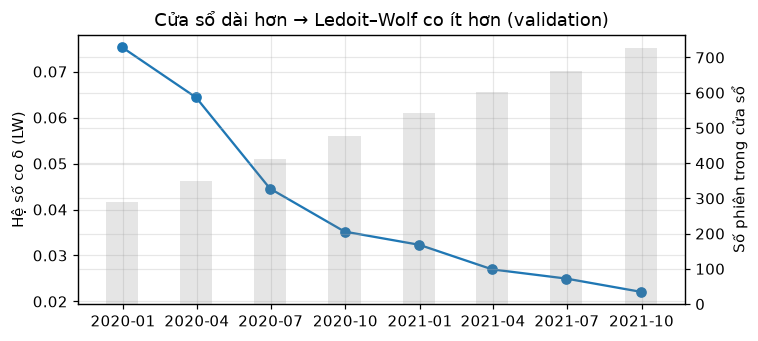

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(diag["decision_date"], diag["lw_shrinkage"], "o-")
ax2 = ax.twinx(); ax2.bar(diag["decision_date"], diag["window_len"], width=40, alpha=0.2, color="gray")
ax.set_ylabel("Hệ số co δ (LW)"); ax2.set_ylabel("Số phiên trong cửa sổ")
ax.set_title("Cửa sổ dài hơn → Ledoit–Wolf co ít hơn (validation)")
fig.tight_layout(); fig.savefig(FIG / "tv4_shrinkage.png"); plt.show()

In [9]:
# Số mã có tỷ trọng > 0,01% mỗi kỳ (ghi chú của phân công: theo dõi Max Sharpe dồn vào vài mã)
diag.set_index("decision_date").filter(like="n_pos_")

,n_pos_min_variance_sample,n_pos_risk_parity_sample,n_pos_max_sharpe_sample,n_pos_min_variance_ledoit_wolf,n_pos_risk_parity_ledoit_wolf,n_pos_max_sharpe_ledoit_wolf
decision_date,,,,,,
2019-12-31,16,29,29,18,29,29
2020-03-31,16,29,29,16,29,29
2020-06-30,14,29,29,16,29,29
2020-09-30,13,29,29,14,29,29
2020-12-31,14,29,29,14,29,29
2021-03-31,15,29,29,15,29,29
2021-06-30,14,29,29,14,29,29
2021-09-30,14,29,29,14,29,29


## 3. Đường biên hiệu quả có ràng buộc tại 30/09/2026 (cho kỳ Q4/2026)

Ngày quyết định 2026-09-30, cửa sổ 756 phiên, μ=capm, Σ=ledoit_wolf, rf=0.0458


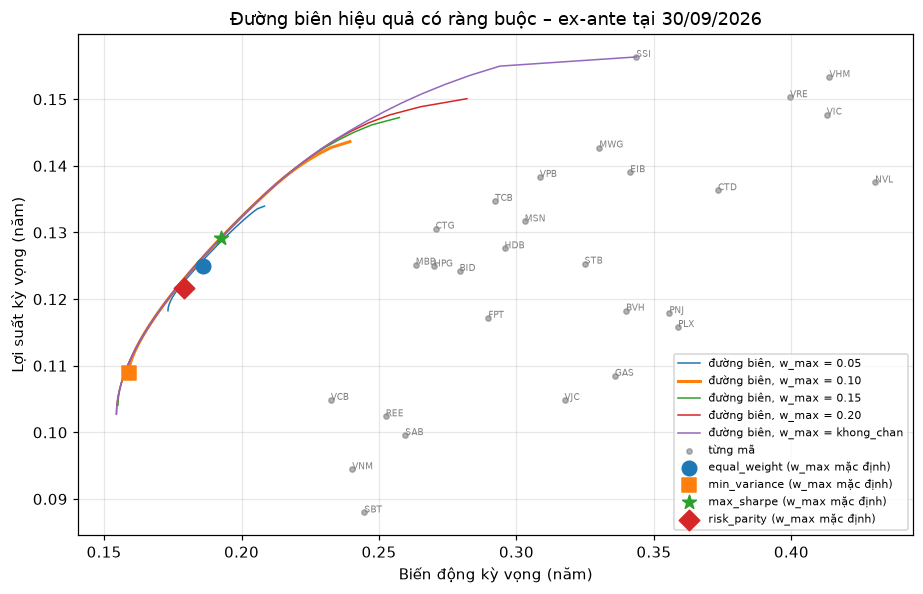

In [10]:
meta = fr.iloc[0]
print(f"Ngày quyết định {meta.decision_date}, cửa sổ {meta.window_len} phiên, μ={meta.mu_method}, "
      f"Σ={meta.cov_method}, rf={meta.rf_annual:.4f}")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for lab, g in fr[fr.point_type == "frontier"].groupby("w_max_label"):
    ax.plot(g["volatility"], g["exp_return"], "-", lw=2 if lab == f"{cfg['portfolio']['w_max']:.2f}" else 1,
            label=f"đường biên, w_max = {lab}")
a = fr[fr.point_type == "asset"]
ax.scatter(a["volatility"], a["exp_return"], s=12, c="gray", alpha=0.6, label="từng mã")
for _, r in a.iterrows():
    ax.annotate(r["label"], (r["volatility"], r["exp_return"]), fontsize=6, color="gray")
s = fr[(fr.point_type == "strategy") & (np.isclose(fr.w_max, cfg["portfolio"]["w_max"]))]
for (_, r), m in zip(s.iterrows(), ["o", "s", "*", "D"]):
    ax.scatter(r["volatility"], r["exp_return"], marker=m, s=90, zorder=5, label=f"{r['label']} (w_max mặc định)")
ax.set_xlabel("Biến động kỳ vọng (năm)"); ax.set_ylabel("Lợi suất kỳ vọng (năm)")
ax.set_title("Đường biên hiệu quả có ràng buộc – ex-ante tại 30/09/2026")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "tv4_frontier_2026Q3.png"); plt.show()

In [11]:
fr[fr.point_type == "strategy"].pivot(index="label", columns="w_max_label",
                                       values=["exp_return", "volatility", "sharpe", "n_positive"]).round(4)

exp_return                                    volatility          \
w_max_label        0.05    0.10    0.15    0.20 khong_chan       0.05    0.10   
label                                                                           
equal_weight     0.1249  0.1249  0.1249  0.1249     0.1249     0.1860  0.1860   
max_sharpe       0.1273  0.1292  0.1292  0.1292     0.1292     0.1893  0.1924   
min_variance     0.1182  0.1090  0.1041  0.1028     0.1027     0.1732  0.1589   
risk_parity      0.1219  0.1216  0.1216  0.1216     0.1216     0.1796  0.1790   

                                         sharpe                          \
w_max_label     0.15    0.20 khong_chan    0.05    0.10    0.15    0.20   
label                                                                     
equal_weight  0.1860  0.1860     0.1860  0.4253  0.4253  0.4253  0.4253   
max_sharpe    0.1925  0.1925     0.1925  0.4304  0.4332  0.4332  0.4332   
min_variance  0.1550  0.1545     0.1545  0.4181  0.3974  0.3757  0.3689   
risk_parity   0.1790  0.1790     0.1790  0.4237  0.4235  0.4235  0.4235   

                        n_positive                               
w_max_label  khong_chan       0.05  0.10  0.15  0.20 khong_chan  
label                                                            
equal_weight     0.4253       28.0  28.0  28.0  28.0       28.0  
max_sharpe       0.4332       28.0  28.0  28.0  28.0       28.0  
min_variance     0.3683       24.0  17.0  13.0  13.0       13.0  
risk_parity      0.4235       28.0  28.0  28.0  28.0       28.0

**Lưu ý khi diễn giải đường biên:** đây là đường biên **trong mẫu** (ex-ante, dựa trên μ, Σ ước lượng),
không phải kết quả đầu tư. Với μ theo CAPM, lợi suất kỳ vọng tỷ lệ với β nên đường biên phản ánh đánh đổi β – biến động.
Hiệu quả thật sự của từng chiến lược xem ở backtest ngoài mẫu (TV5).

## 4. (CHỈ SAU 03/11) Sai số dự báo trên tập test

Bỏ dấu `#` và chạy **một lần** sau khi đóng băng. Kết quả chỉ để báo cáo, không dùng để đổi thiết kế.

In [12]:
# for p in tv4_forecast.run("test", with_frontier=False):
#     print("ghi", p.relative_to(ROOT))
# pd.read_csv(ROOT / "outputs/forecast_error_test.csv")